In [1]:
# =========================================================================
#  DEPENDENCIAS — EJECUTAR ESTA CELDA PRIMERO
# -------------------------------------------------------------------------
#  Revisa paquete por paquete e instala UNICAMENTE los que falten.
# =========================================================================
import importlib.metadata as metadata
import importlib.util
import subprocess
import sys

REQUISITOS = {
    "numpy": "numpy",
    "pandas": "pandas",
    "pyarrow": "pyarrow",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "psutil": "psutil",
    "joblib": "joblib",
    "torch": "torch",
}

faltantes = [pip_name for modulo, pip_name in REQUISITOS.items()
             if importlib.util.find_spec(modulo) is None]

if faltantes:
    print(f"Faltan {len(faltantes)} paquete(s): {', '.join(faltantes)}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltantes], check=True)
    print("Instalacion terminada.")
else:
    print("Todas las dependencias ya estaban instaladas: no se descargo nada.")

print("\nVersiones en uso")
print("-" * 36)
for pip_name in REQUISITOS.values():
    try:
        print(f"  {pip_name:<18} {metadata.version(pip_name)}")
    except metadata.PackageNotFoundError:
        print(f"  {pip_name:<18} (no detectada)")

Todas las dependencias ya estaban instaladas: no se descargo nada.

Versiones en uso
------------------------------------
  numpy              2.3.5
  pandas             2.3.3
  pyarrow            26.0.1
  scikit-learn       1.9.1
  matplotlib         3.10.0
  psutil             5.9.8
  joblib             1.6.0
  torch              2.15.0


# Laboratorio 1 — Fase C: Stacking Ensemble y Evaluación Final
### Opción B: Predicción Científica — *HIGGS Boson Dataset*

**Curso:** Fundamentos de Aprendizaje Profundo y Aplicaciones — 2-2026
**Grupo:** 6 · **Integrante:** Cristopher Angulo Ahumada (trabajo individual)

---

## 1. Antecedentes

| Notebook | Productos |
|---|---|
| `01_EDA_y_Preprocessing.ipynb` | Submuestra de 1.000.000 de filas, particiones estratificadas y la evidencia de ausencia de *data leakage* |
| `02_Modelos_Base.ipynb` | 51 variables tras el *feature engineering* y **3 modelos base** persistidos en `checkpoints/`, cada uno con una de las tres mejores arquitecturas distintas del estudio de Optuna y entrenado sobre su propia muestra Bootstrap |

## 2. Contenido

| Etapa | Descripción |
|---|---|
| **C.1** | Reconstrucción de los modelos base a partir de sus checkpoints `.pt` |
| **C.2** | **Meta-red de Stacking con pesos entrenables** |
| **C.3** | Comparación cuantitativa: modelos individuales, promedio simple y Stacking |
| **C.4** | **Evaluación crítica sobre el conjunto de Test** |
| **C.5** | Discusión y conclusiones técnicas |

## 3. Protocolo de evaluación

> **El conjunto de Test se utiliza una única vez, en la etapa C.4.** No intervino en el
> entrenamiento de los modelos base, ni en el criterio de Early Stopping, ni en la búsqueda de
> hiperparámetros, ni en el ajuste de la meta-red. Esa restricción es la condición necesaria para
> que la estimación final del desempeño sea insesgada.

---
# Celda 1 — Imports, reproducibilidad y utilidades

In [2]:
# Incrusta las figuras en las salidas del notebook.
%matplotlib inline

import gc
import shutil
import os
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")

SEED = 42


def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {DEVICE}")
if not torch.cuda.is_available():
    print(f"Hilos de CPU disponibles: {torch.get_num_threads()}")


def mem_report(tag: str = "") -> None:
    rss = psutil.Process(os.getpid()).memory_info().rss / 1e9
    vm = psutil.virtual_memory()
    print(f"[RAM] {tag:<34} proceso: {rss:5.2f} GB | sistema: {vm.used/1e9:5.2f}/{vm.total/1e9:.2f} GB ({vm.percent:.0f}%)")


mem_report("inicio")

Dispositivo: cpu
Hilos de CPU disponibles: 8
[RAM] inicio                             proceso:  0.32 GB | sistema: 20.44/34.16 GB (60%)


---
# Celda 2 — Entorno, rutas y carga de los datos

Se recuperan las particiones escaladas con las 51 variables generadas por el notebook 02. Las
figuras y la tabla comparativa de esta fase se guardan en `reports/figures` y `reports/tables` del
repositorio, y se replican en Drive mediante `espejar()`.

In [3]:
try:
    import google.colab  # noqa: F401

    EN_COLAB = True
except ModuleNotFoundError:
    EN_COLAB = False


def raiz_del_repo():
    actual = Path.cwd().resolve()
    for candidata in (actual, *actual.parents):
        if (candidata / "src").is_dir() and (candidata / "notebooks").is_dir():
            return candidata
    return actual


def buscar_drive_local():
    for letra in "GHIJKLDEF":
        for nombre in ("Mi unidad", "My Drive"):
            ruta = Path(f"{letra}:/{nombre}")
            try:
                if ruta.is_dir():
                    return ruta
            except OSError:
                continue
    return None


REPO = raiz_del_repo()

if EN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Lab1-DL")
    ENTORNO = "Google Colab, con Drive montado"
else:
    unidad = buscar_drive_local()
    if unidad is not None:
        PROJECT_DIR = unidad / "Lab1-DL"
        ENTORNO = f"Local, con Google Drive para escritorio en {unidad}"
    else:
        PROJECT_DIR = REPO
        ENTORNO = "Local, sin Drive: los artefactos quedan en el repositorio"

PROC_DIR = PROJECT_DIR / "data" / "processed"
CKPT_DIR = PROJECT_DIR / "checkpoints"
# Los artefactos pesados (parquet, splits, checkpoints) van a Drive, porque su
# razon de ser es sobrevivir a una interrupcion.
#
# La evidencia del informe (figuras, tablas y el reporte de profiling) pesa poco
# y se guarda en LOS DOS destinos: el repositorio, que es donde se versiona y
# por donde se revisa el trabajo, y Drive, que conserva la copia de respaldo
# junto al resto de los artefactos. El repositorio es el destino primario y la
# copia a Drive se hace archivo por archivo en cuanto cada uno se escribe, de
# modo que una interrupcion no deje el respaldo a medias.
REPORT_DIR = REPO / "reports"
FIG_DIR = REPORT_DIR / "figures"          # figuras .png
PROFILING_DIR = REPORT_DIR / "profiling"  # reporte html de ydata-profiling
TABLE_DIR = REPORT_DIR / "tables"         # tablas .csv

# Destinos de la evidencia: el primero es el primario; los siguientes, copias.
DIRS_INFORME = [REPORT_DIR]
if PROJECT_DIR != REPO:
    DIRS_INFORME.append(PROJECT_DIR / "reports")


def espejar(ruta: Path) -> list:
    """Replica en los destinos secundarios un archivo escrito en el primario."""
    copias = []
    for base in DIRS_INFORME[1:]:
        destino = base / ruta.relative_to(DIRS_INFORME[0])
        destino.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(ruta, destino)
        copias.append(destino)
    return copias


def guardar_figura(nombre: str, dpi: int = 120) -> Path:
    """Guarda la figura actual en el repositorio y la replica en Drive."""
    ruta = FIG_DIR / nombre
    plt.savefig(ruta, dpi=dpi, bbox_inches="tight")
    espejar(ruta)
    return ruta
for carpeta in (PROC_DIR, CKPT_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)
for base in DIRS_INFORME:
    for sub in ("figures", "profiling", "tables"):
        (base / sub).mkdir(parents=True, exist_ok=True)

SPLITS_FE_PATH = PROC_DIR / "splits_escalados_fe.npz"
CKPT_META = CKPT_DIR / "meta_stacking.pt"

print(f"Entorno detectado: {ENTORNO}\n")

if not SPLITS_FE_PATH.exists():
    raise FileNotFoundError(
        f"No se encuentra {SPLITS_FE_PATH}. Ejecuta primero 02_Modelos_Base.ipynb."
    )

d = np.load(SPLITS_FE_PATH, allow_pickle=True)
X_train, y_train = d["X_train"], d["y_train"]
X_val, y_val = d["X_val"], d["y_val"]
X_test, y_test = d["X_test"], d["y_test"]
FEATURES = list(d["features"])
del d
gc.collect()

N_FEATURES = X_train.shape[1]
Xva_t = torch.from_numpy(X_val)
yva_t = torch.from_numpy(y_val.astype(np.float32))
Xte_t = torch.from_numpy(X_test)
yte_t = torch.from_numpy(y_test.astype(np.float32))

print(f"Features: {N_FEATURES}")
print(f"{'Particion':<12}{'Filas':>12}{'% senal':>12}")
print("-" * 36)
for nombre, Xs, ys in [("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]:
    print(f"{nombre:<12}{len(Xs):>12,}{100*ys.mean():>11.3f}%")
mem_report("tras cargar los splits")

Entorno detectado: Local, con Google Drive para escritorio en G:\Mi unidad

Features: 51
Particion          Filas     % senal
------------------------------------
Train            699,999     52.954%
Validation       150,000     52.954%
Test             150,000     52.954%
[RAM] tras cargar los splits             proceso:  0.53 GB | sistema: 20.64/34.16 GB (60%)


---
# Celda 3 — Fase C.1: Reconstrucción de los modelos base

Los checkpoints almacenan el `state_dict` **y la configuración de la arquitectura**, de modo que
cada modelo puede reconstruirse exactamente sin necesidad de recordar los hiperparámetros con que
fue entrenado. Esa es la razón por la cual se persistió un diccionario y no únicamente los pesos.

Como verificación de integridad, se recalcula el ROC-AUC de validación de cada modelo y se compara
con el valor registrado en su checkpoint. La coincidencia de ambos valores acredita que la
reconstrucción fue correcta.

In [4]:
from sklearn.metrics import roc_auc_score


def init_pesos(modulo: nn.Module, es_salida: bool = False) -> None:
    """Inicializacion explicita segun el tipo de capa (He / Xavier)."""
    if isinstance(modulo, nn.Linear):
        if es_salida:
            nn.init.xavier_uniform_(modulo.weight)
        else:
            nn.init.kaiming_normal_(modulo.weight, mode="fan_in", nonlinearity="relu")
        if modulo.bias is not None:
            nn.init.zeros_(modulo.bias)
    elif isinstance(modulo, nn.BatchNorm1d):
        nn.init.ones_(modulo.weight)
        nn.init.zeros_(modulo.bias)


class FFNN(nn.Module):
    """Misma arquitectura del notebook 02, para poder recargar los pesos."""

    def __init__(self, entrada: int, ocultas=(256, 128, 64), dropout: float = 0.3,
                 usar_batchnorm: bool = True):
        super().__init__()
        capas = []
        prev = entrada
        for h in ocultas:
            capas.append(nn.Linear(prev, h, bias=not usar_batchnorm))
            if usar_batchnorm:
                capas.append(nn.BatchNorm1d(h))
            capas.append(nn.ReLU(inplace=True))
            if dropout > 0:
                capas.append(nn.Dropout(dropout))
            prev = h
        self.cuerpo = nn.Sequential(*capas)
        self.salida = nn.Linear(prev, 1)
        self.cuerpo.apply(lambda m: init_pesos(m, es_salida=False))
        init_pesos(self.salida, es_salida=True)

    def forward(self, x):
        return self.salida(self.cuerpo(x)).view(-1)


@torch.no_grad()
def logits_de(modelo, X, batch=8192):
    """Logits de un modelo sobre un tensor, por lotes y sin construir el grafo."""
    modelo.eval()
    return torch.cat([modelo(X[i:i + batch]) for i in range(0, len(X), batch)])


rutas_ckpt = sorted(CKPT_DIR.glob("modelo_base_*.pt"))
if not rutas_ckpt:
    raise FileNotFoundError(f"No hay checkpoints en {CKPT_DIR}. Ejecuta 02_Modelos_Base.ipynb.")

modelos_base, info = [], []
for ruta in rutas_ckpt:
    ckpt = torch.load(ruta, map_location="cpu", weights_only=False)
    cfg = ckpt["config"]
    modelo = FFNN(cfg["entrada"], tuple(cfg["ocultas"]), cfg["dropout"])
    modelo.load_state_dict(ckpt["state_dict"])
    modelo.eval()
    modelos_base.append(modelo)

    auc_recalculado = roc_auc_score(y_val, logits_de(modelo, Xva_t).numpy())
    info.append({
        "checkpoint": ruta.name,
        "arquitectura": "-".join(map(str, cfg["ocultas"])),
        "dropout": round(cfg["dropout"], 4),
        "epoca_guardada": ckpt["epoca"],
        "auc_en_checkpoint": round(ckpt["auc_va"], 5),
        "auc_recalculado": round(auc_recalculado, 5),
        "coincide": abs(auc_recalculado - ckpt["auc_va"]) < 1e-4,
    })

M_MODELOS = len(modelos_base)
df_info = pd.DataFrame(info)
display(df_info)

if df_info["coincide"].all():
    print(f"\nLos {M_MODELOS} modelos se reconstruyeron correctamente: el AUC recalculado")
    print("coincide con el que quedo registrado en cada checkpoint.")
else:
    print("\nATENCION: algun modelo no reproduce el AUC de su checkpoint.")

,checkpoint,arquitectura,dropout,epoca_guardada,auc_en_checkpoint,auc_recalculado,coincide
0,modelo_base_1.pt,512-256-128,0.3019,33,0.85341,0.85341,True
1,modelo_base_2.pt,256-128-64,0.2745,37,0.84993,0.84993,True
2,modelo_base_3.pt,128-64,0.4400,35,0.83332,0.83332,True



Los 3 modelos se reconstruyeron correctamente: el AUC recalculado
coincide con el que quedo registrado en cada checkpoint.


---
# Celda 4 — Fase C.2: La meta-red de Stacking

## 4.1 Promediar no equivale a combinar

El procedimiento más simple para unir varios modelos consiste en promediar sus predicciones,
asignando a cada uno el mismo peso. Ese esquema supone que **todos los modelos son igualmente
confiables**, supuesto que rara vez se verifica; cuando no se cumple, el promedio arrastra al
conjunto hacia el desempeño del peor de sus miembros.

El **Stacking**, propuesto por Wolpert [13], entrena un segundo modelo —el *meta-aprendiz*— cuya
única función es determinar **cómo ponderar** a los modelos base, inferiendo de los datos que un
modelo merece mayor peso que otro. A diferencia del Bagging [11], donde la combinación es un
promedio con pesos fijos, aquí la regla de combinación se aprende.

## 4.2 Implementación

La implementación sigue el diseño de la clase `StackingEnsemble` del código base de la asignatura:

1. **Se congelan los modelos base** (`requires_grad = False`). Al haber sido entrenados ya mediante
   Bootstrap, en esta fase operan exclusivamente como extractores de predicciones.
2. En el paso `forward`, la entrada se evalúa en los M modelos y **sus logits se concatenan** en un
   vector de dimensión `M × d_out`.
3. Ese vector alimenta una **capa lineal entrenable**, que produce la predicción final.

La clase resuelve además una cuestión relevante mediante la sobreescritura de `.train()`: aunque el
ensamble se encuentre en modo entrenamiento mientras se ajusta la meta-capa, los modelos base deben
permanecer en `.eval()`. En caso contrario, su Dropout se activaría y las estadísticas de sus capas
de Batch Normalization continuarían actualizándose, alterando precisamente las predicciones que la
meta-red intenta aprender a combinar.

## 4.3 Inicialización de la meta-capa: desviación justificada del código base

El código base inicializa la meta-capa con Xavier [5]. Con solo M = 3 entradas, esa inicialización
puede entregar **pesos negativos**, en cuyo caso el ensamble parte invirtiendo el ordenamiento de
las predicciones —ROC-AUC por debajo de 0,5— y debe recorrer el espacio de parámetros hasta
alcanzar el signo correcto antes de poder mejorar. El comportamiento se verificó experimentalmente
durante las pruebas de la implementación.

Por ese motivo la meta-capa se inicializa en el **promedio simple**: peso 1/M para cada modelo y
sesgo nulo. De este modo el Stacking parte exactamente en la línea base que debe superar, y el
entrenamiento solo puede ajustarla. El parámetro `init_promedio=False` restituye el comportamiento
original del código base.

## 4.4 Conjunto de ajuste de la meta-red

Si el meta-aprendiz observara las predicciones de los modelos base **sobre los datos con que esos
modelos fueron entrenados**, registraría un desempeño artificialmente elevado, dado que cada modelo
ha memorizado parcialmente esas observaciones; en consecuencia, aprendería a asignarles una
confianza superior a la que les corresponde.

Por esa razón la meta-red se entrena sobre el **conjunto de Validación**, que ningún modelo base
utilizó para ajustar sus pesos. Y para que su propio criterio de Early Stopping no se evalúe sobre
las mismas observaciones que está ajustando, Validación se divide en dos subconjuntos: **70 % para
meta-entrenamiento y 30 % para meta-validación**.

El conjunto de Test permanece sin utilizar.

In [5]:
class StackingEnsemble(nn.Module):
    """Meta-modelo de Stacking con pesos entrenables.

    Congela los M modelos base, concatena sus logits y los combina mediante una
    capa lineal entrenable. Es la clase del codigo base con dos ajustes:

    1. Los modelos de este laboratorio devuelven forma (batch,) en vez de
       (batch, d_out), asi que cada salida se reconforma antes de concatenar.
    2. La meta-capa se inicializa en el promedio simple (peso 1/M, sesgo 0) en
       vez de Xavier, por el motivo documentado mas abajo.
    """

    def __init__(self, modelos_base, d_out: int = 1, init_promedio: bool = True):
        super().__init__()
        self.num_modelos = len(modelos_base)
        self.d_out = d_out
        self.modelos_base = nn.ModuleList(modelos_base)

        # Congelar: ya fueron entrenados via Bootstrap
        for bm in self.modelos_base:
            bm.eval()
            for p in bm.parameters():
                p.requires_grad = False

        self.meta_learner = nn.Linear(self.num_modelos * d_out, d_out)

        if init_promedio:
            # Se parte del PROMEDIO SIMPLE: peso 1/M para cada modelo y sesgo 0.
            # El codigo base usa Xavier aqui, pero con solo M entradas Xavier
            # puede entregar pesos negativos, y entonces el ensamble arranca
            # INVIRTIENDO la prediccion (AUC por debajo de 0.5) y tiene que
            # "viajar" hasta el signo correcto antes de poder mejorar.
            # Partiendo del promedio, el Stacking empieza exactamente en la
            # linea base que debe superar, y el entrenamiento solo lo ajusta.
            with torch.no_grad():
                self.meta_learner.weight.fill_(1.0 / self.num_modelos)
                self.meta_learner.bias.zero_()
        else:
            init_pesos(self.meta_learner, es_salida=True)

    def train(self, mode: bool = True):
        """Los modelos base permanecen SIEMPRE en eval, aunque el ensamble entrene."""
        super().train(mode)
        for bm in self.modelos_base:
            bm.eval()
        return self

    def meta_features(self, x):
        """Logits de los M modelos base concatenados: (batch, M * d_out)."""
        with torch.no_grad():
            salidas = [bm(x).view(x.size(0), -1) for bm in self.modelos_base]
        return torch.cat(salidas, dim=1)

    def forward(self, x):
        return self.meta_learner(self.meta_features(x)).view(-1)


ensamble = StackingEnsemble(modelos_base, d_out=1)
entrenables = sum(p.numel() for p in ensamble.parameters() if p.requires_grad)
congelados = sum(p.numel() for p in ensamble.parameters() if not p.requires_grad)

print(ensamble.meta_learner)
print(f"\nParametros entrenables (meta-capa): {entrenables:,}")
print(f"Parametros congelados (modelos base): {congelados:,}")
print(f"\nSolo se entrena el {100*entrenables/(entrenables+congelados):.4f}% de los parametros:")
print("el Stacking aprende COMO combinar, no vuelve a aprender el problema.")

w0 = ensamble.meta_learner.weight.detach().numpy().ravel()
print()
print(f"Pesos iniciales: {np.round(w0, 4)}  (1/M = {1/M_MODELOS:.4f} cada uno)")
print("El ensamble parte exactamente en el promedio simple de los modelos base:")
print("ese es el piso que el entrenamiento de la meta-red debe mejorar.")

Linear(in_features=3, out_features=1, bias=True)

Parametros entrenables (meta-capa): 4
Parametros congelados (modelos base): 262,019

Solo se entrena el 0.0015% de los parametros:
el Stacking aprende COMO combinar, no vuelve a aprender el problema.

Pesos iniciales: [0.3333 0.3333 0.3333]  (1/M = 0.3333 cada uno)
El ensamble parte exactamente en el promedio simple de los modelos base:
ese es el piso que el entrenamiento de la meta-red debe mejorar.


---
# Celda 5 — Entrenamiento de la meta-red

In [6]:
from sklearn.model_selection import train_test_split

# Validacion se parte en meta-entrenamiento y meta-validacion, estratificando.
idx = np.arange(len(X_val))
idx_mtr, idx_mva = train_test_split(idx, test_size=0.30, stratify=y_val, random_state=SEED)
Xmtr, ymtr = Xva_t[idx_mtr], yva_t[idx_mtr]
Xmva, ymva = Xva_t[idx_mva], yva_t[idx_mva]
print(f"Meta-entrenamiento: {len(Xmtr):,} filas   |   meta-validacion: {len(Xmva):,} filas")

n_pos = float(ymtr.sum()); POS_WEIGHT_META = (len(ymtr) - n_pos) / n_pos
print(f"pos_weight de la meta-red: {POS_WEIGHT_META:.4f}\n")


@torch.no_grad()
def evaluar_ensamble(modelo, X, y, batch=8192):
    modelo.eval()
    criterio = nn.BCEWithLogitsLoss(reduction="sum")
    total, logits = 0.0, []
    for i in range(0, len(X), batch):
        out = modelo(X[i:i + batch])
        total += criterio(out, y[i:i + batch]).item()
        logits.append(out)
    logits = torch.cat(logits)
    return total / len(X), roc_auc_score(y.numpy(), logits.numpy())


set_seed(SEED)
opt = torch.optim.AdamW(ensamble.meta_learner.parameters(), lr=5e-3, weight_decay=1e-4)
criterio = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([POS_WEIGHT_META], dtype=torch.float32))

EPOCAS_META, PACIENCIA_META, BATCH_META = 80, 10, 2048
hist_meta = {"loss_tr": [], "loss_va": [], "auc_va": []}
mejor_loss, mejor_epoca, sin_mejora, mejores_pesos = float("inf"), -1, 0, None
t0 = time.time()

for epoca in range(1, EPOCAS_META + 1):
    ensamble.train()                      # los modelos base siguen en eval
    orden = torch.randperm(len(Xmtr))
    suma = 0.0
    for i in range(0, len(Xmtr), BATCH_META):
        sel = orden[i:i + BATCH_META]
        if len(sel) < 2:
            continue
        opt.zero_grad(set_to_none=True)
        perdida = criterio(ensamble(Xmtr[sel]), ymtr[sel])
        perdida.backward()
        opt.step()
        suma += perdida.item() * len(sel)

    loss_tr = suma / len(Xmtr)
    loss_va, auc_va = evaluar_ensamble(ensamble, Xmva, ymva)
    hist_meta["loss_tr"].append(loss_tr)
    hist_meta["loss_va"].append(loss_va)
    hist_meta["auc_va"].append(auc_va)

    if loss_va < mejor_loss - 1e-6:
        mejor_loss, mejor_epoca, sin_mejora = loss_va, epoca, 0
        mejores_pesos = {k: v.detach().clone() for k, v in ensamble.meta_learner.state_dict().items()}
        torch.save({"state_dict": mejores_pesos, "epoca": epoca, "loss_va": loss_va,
                    "auc_va": auc_va, "num_modelos": M_MODELOS}, CKPT_META)
    else:
        sin_mejora += 1

    if epoca % 10 == 0 or epoca == 1:
        print(f"  epoca {epoca:3d} | loss_tr {loss_tr:.5f} | loss_va {loss_va:.5f} "
              f"| auc_va {auc_va:.5f} | {time.time()-t0:5.0f}s")

    if sin_mejora >= PACIENCIA_META:
        print(f"  Early Stopping en la epoca {epoca} (mejor: epoca {mejor_epoca})")
        break

ensamble.meta_learner.load_state_dict(mejores_pesos)
print(f"\nMeta-red entrenada en {time.time()-t0:.0f}s | mejor epoca {mejor_epoca}")
print(f"Checkpoint guardado en {CKPT_META}")

Meta-entrenamiento: 105,000 filas   |   meta-validacion: 45,000 filas
pos_weight de la meta-red: 0.8884

  epoca   1 | loss_tr 0.44495 | loss_va 0.46846 | auc_va 0.85707 |     0s
  epoca  10 | loss_tr 0.44251 | loss_va 0.46589 | auc_va 0.85849 |     4s
  epoca  20 | loss_tr 0.44252 | loss_va 0.46589 | auc_va 0.85847 |     7s
  epoca  30 | loss_tr 0.44252 | loss_va 0.46604 | auc_va 0.85850 |    10s
  Early Stopping en la epoca 32 (mejor: epoca 22)

Meta-red entrenada en 11s | mejor epoca 22
Checkpoint guardado en G:\Mi unidad\Lab1-DL\checkpoints\meta_stacking.pt


Pesos de la meta-capa (uno por modelo base):

Modelo            Peso   Peso relativo   AUC individual (val)
------------------------------------------------------------
base_1          0.6401          55.9%   0.85341  #################
base_2          0.4547          39.7%   0.84993  ############
base_3         -0.0493           4.3%   0.83332  #
sesgo          -0.0469

Si el Stacking fuera un promedio simple, los tres pesos serian identicos
y el sesgo cero. Las diferencias muestran la ponderacion aprendida.


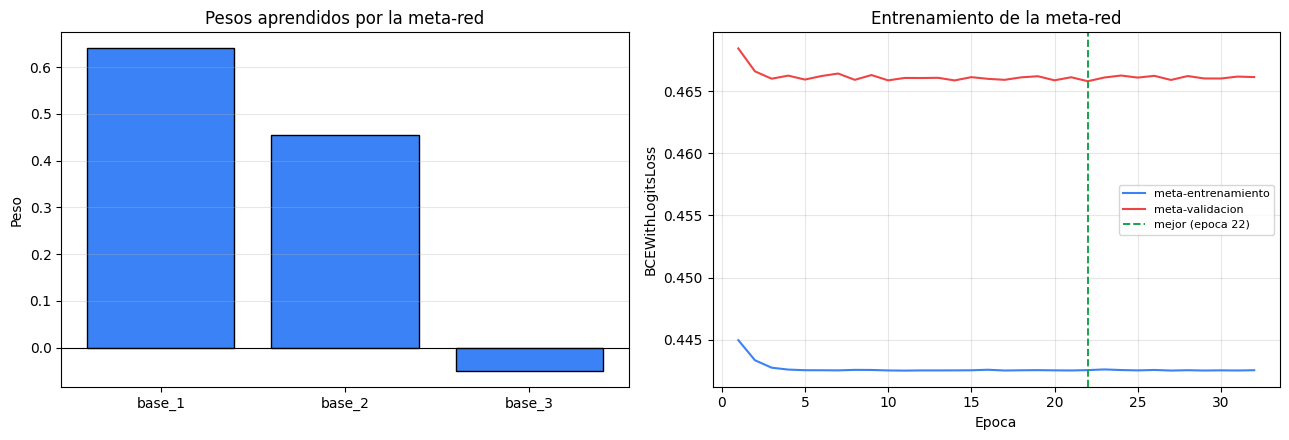

In [7]:
# --- Pesos aprendidos: que modelo resulto mas confiable --------------------
pesos = ensamble.meta_learner.weight.detach().numpy().ravel()
sesgo = float(ensamble.meta_learner.bias.detach().numpy().ravel()[0])

print("Pesos de la meta-capa (uno por modelo base):")
print(f"\n{'Modelo':<12}{'Peso':>10}{'Peso relativo':>16}   AUC individual (val)")
print("-" * 60)
suma_abs = np.abs(pesos).sum()
for i, w in enumerate(pesos):
    rel = abs(w) / suma_abs
    auc_i = df_info.loc[i, "auc_recalculado"]
    barra = "#" * int(round(rel * 30))
    print(f"{'base_'+str(i+1):<12}{w:>10.4f}{rel:>15.1%}   {auc_i:.5f}  {barra}")
print(f"{'sesgo':<12}{sesgo:>10.4f}")

print("\nSi el Stacking fuera un promedio simple, los tres pesos serian identicos")
print("y el sesgo cero. Las diferencias muestran la ponderacion aprendida.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar([f"base_{i+1}" for i in range(M_MODELOS)], pesos, color="#3b82f6", edgecolor="black")
ax[0].axhline(0, color="black", lw=0.8)
ax[0].set_title("Pesos aprendidos por la meta-red")
ax[0].set_ylabel("Peso")
ax[0].grid(alpha=0.3, axis="y")

epocas = range(1, len(hist_meta["loss_tr"]) + 1)
ax[1].plot(epocas, hist_meta["loss_tr"], label="meta-entrenamiento", color="#3b82f6")
ax[1].plot(epocas, hist_meta["loss_va"], label="meta-validacion", color="#ef4444")
ax[1].axvline(mejor_epoca, color="#16a34a", ls="--", lw=1.4, label=f"mejor (epoca {mejor_epoca})")
ax[1].set_title("Entrenamiento de la meta-red")
ax[1].set_xlabel("Epoca"); ax[1].set_ylabel("BCEWithLogitsLoss")
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout()
guardar_figura("meta_stacking.png")
plt.show()

---
# Celda 6 — Fases C.3 y C.4: Evaluación sobre el conjunto de Test

En esta celda se utiliza el conjunto de Test por primera y única vez. Se comparan cinco
predictores:

- Los **3 modelos base** considerados por separado.
- El **promedio simple** de los tres, que constituye la línea base ingenua.
- El **Stacking**, del que se espera que supere o al menos iguale a ambas referencias.

La métrica principal es el **ROC-AUC**, que cuantifica la capacidad de ordenar correctamente los
eventos de señal por sobre los de fondo con independencia del umbral de decisión. Se acompaña de
**PR-AUC**, **F1** y **exactitud**, conforme al conjunto de métricas exigido en el enunciado.

In [8]:
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_recall_curve, roc_curve,
)


def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-z))


# Logits de cada modelo base sobre Test
logits_base_test = [logits_de(m, Xte_t).numpy() for m in modelos_base]
probs_base_test = [sigmoide(l) for l in logits_base_test]

# Promedio simple
prob_promedio = np.mean(probs_base_test, axis=0)

# Stacking
ensamble.eval()
with torch.no_grad():
    logits_stack = torch.cat(
        [ensamble(Xte_t[i:i + 8192]) for i in range(0, len(Xte_t), 8192)]
    ).numpy()
prob_stack = sigmoide(logits_stack)


def metricas(y_true, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob),
        "F1": f1_score(y_true, pred),
        "Exactitud": accuracy_score(y_true, pred),
    }


filas = []
for i, p in enumerate(probs_base_test, start=1):
    filas.append({"Predictor": f"Modelo base {i}", **metricas(y_test, p)})
filas.append({"Predictor": "Promedio simple", **metricas(y_test, prob_promedio)})
filas.append({"Predictor": "STACKING", **metricas(y_test, prob_stack)})

df_comp = pd.DataFrame(filas).set_index("Predictor")
display(df_comp.round(5))

auc_individual = max(df_comp.loc[[f"Modelo base {i}" for i in range(1, M_MODELOS + 1)], "ROC-AUC"])
auc_promedio = df_comp.loc["Promedio simple", "ROC-AUC"]
auc_stack = df_comp.loc["STACKING", "ROC-AUC"]

print(f"\nMejor modelo individual : {auc_individual:.5f}")
print(f"Promedio simple         : {auc_promedio:.5f}  ({auc_promedio-auc_individual:+.5f} vs individual)")
print(f"Stacking                : {auc_stack:.5f}  ({auc_stack-auc_individual:+.5f} vs individual, "
      f"{auc_stack-auc_promedio:+.5f} vs promedio)")

if auc_stack >= auc_promedio and auc_stack >= auc_individual:
    print("\n-> El Stacking SUPERA tanto al mejor modelo individual como al promedio simple.")
elif auc_stack >= auc_individual:
    print("\n-> El Stacking supera al mejor individual, pero no al promedio simple.")
else:
    print("\n-> El Stacking NO supera al mejor modelo individual: ver la discusion mas abajo.")

,ROC-AUC,PR-AUC,F1,Exactitud
Predictor,,,,
Modelo base 1,0.85316,0.86499,0.77918,0.76921
Modelo base 2,0.84880,0.86094,0.77860,0.76425
Modelo base 3,0.83279,0.84582,0.75891,0.74967
Promedio simple,0.85282,0.86469,0.78046,0.76893
STACKING,0.85572,0.86763,0.78115,0.77126



Mejor modelo individual : 0.85316
Promedio simple         : 0.85282  (-0.00034 vs individual)
Stacking                : 0.85572  (+0.00256 vs individual, +0.00290 vs promedio)

-> El Stacking SUPERA tanto al mejor modelo individual como al promedio simple.


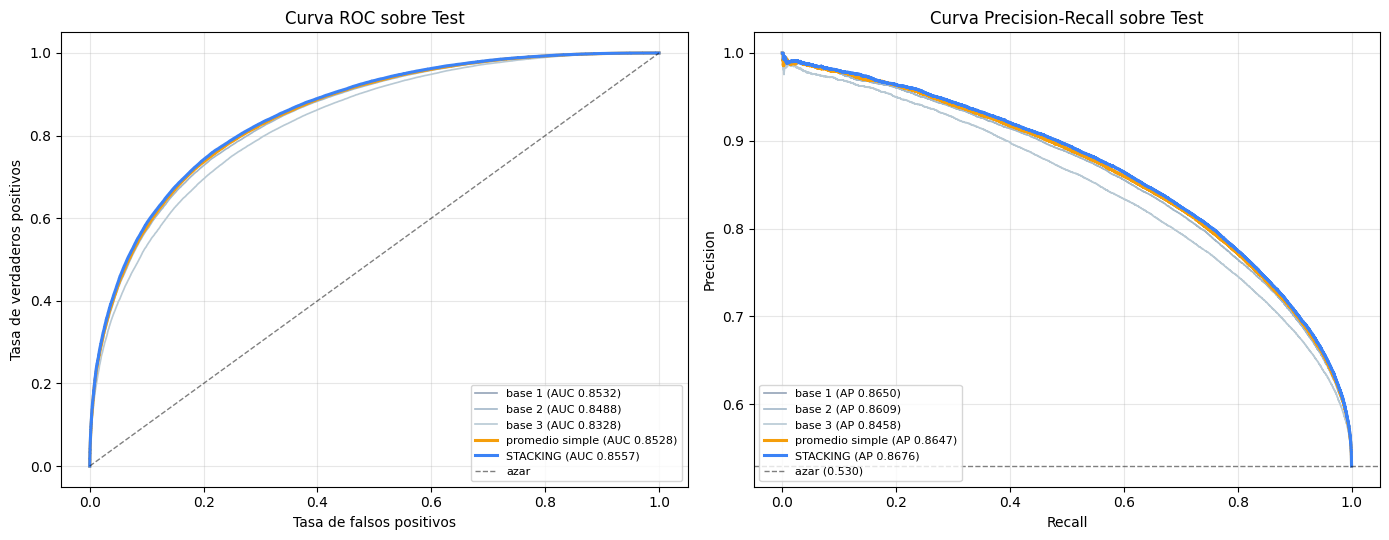

In [9]:
# --- Curvas ROC y Precision-Recall ----------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

colores_base = ["#94a3b8", "#a3b8c9", "#b8c9d4"]
for i, p in enumerate(probs_base_test):
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, lw=1.2, color=colores_base[i % len(colores_base)],
               label=f"base {i+1} (AUC {roc_auc_score(y_test, p):.4f})")
for p, color, nombre in [(prob_promedio, "#f59e0b", "promedio simple"),
                         (prob_stack, "#3b82f6", "STACKING")]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, lw=2.2, color=color, label=f"{nombre} (AUC {roc_auc_score(y_test, p):.4f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5, label="azar")
ax[0].set_xlabel("Tasa de falsos positivos"); ax[0].set_ylabel("Tasa de verdaderos positivos")
ax[0].set_title("Curva ROC sobre Test"); ax[0].legend(fontsize=8, loc="lower right"); ax[0].grid(alpha=0.3)

for i, p in enumerate(probs_base_test):
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, lw=1.2, color=colores_base[i % len(colores_base)],
               label=f"base {i+1} (AP {average_precision_score(y_test, p):.4f})")
for p, color, nombre in [(prob_promedio, "#f59e0b", "promedio simple"),
                         (prob_stack, "#3b82f6", "STACKING")]:
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, lw=2.2, color=color, label=f"{nombre} (AP {average_precision_score(y_test, p):.4f})")
ax[1].axhline(y_test.mean(), color="black", ls="--", lw=1, alpha=0.5,
              label=f"azar ({y_test.mean():.3f})")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Curva Precision-Recall sobre Test"); ax[1].legend(fontsize=8, loc="lower left")
ax[1].grid(alpha=0.3)

plt.tight_layout()
guardar_figura("curvas_test.png")
plt.show()

---
# Celda 7 — Matriz de confusión e interpretación física

La matriz de confusión permite traducir el desempeño del modelo al lenguaje del problema. En un
experimento de física de partículas, cada celda tiene una consecuencia experimental distinta:

| Celda | Significado | Consecuencia experimental |
|---|---|---|
| **Verdadero positivo** | Evento de Higgs correctamente identificado | Constituye el objetivo del análisis |
| **Falso negativo** | Evento de Higgs descartado como fondo | **Pérdida de señal**: colisiones que consumieron tiempo de acelerador y se descartan |
| **Falso positivo** | Evento de fondo clasificado como señal | Contamina la muestra y diluye la significancia estadística del resultado |
| **Verdadero negativo** | Evento de fondo correctamente descartado | Es lo que permite reducir el volumen de datos a analizar |

La asimetría entre ambos tipos de error es metodológicamente relevante: en la práctica experimental
el umbral de decisión se calibra en función de cuál de los dos resulte más costoso para el análisis
posterior.

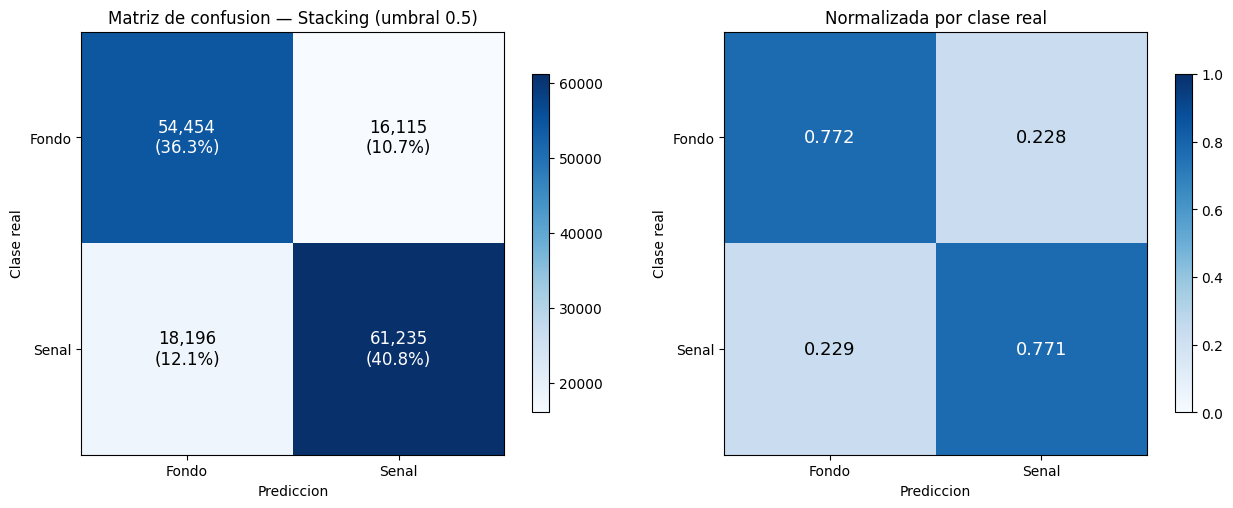

REPORTE DE CLASIFICACION — Stacking sobre Test
               precision    recall  f1-score   support

        Fondo     0.7495    0.7716    0.7604     70569
Senal (Higgs)     0.7917    0.7709    0.7812     79431

     accuracy                         0.7713    150000
    macro avg     0.7706    0.7713    0.7708    150000
 weighted avg     0.7718    0.7713    0.7714    150000

LECTURA EN EL CONTEXTO DEL PROBLEMA
De 79,431 colisiones de senal presentes en el Test:
   61,235 fueron detectadas            (77.09% de recall)
   18,196 se perdieron como fondo      (22.91%)

De 70,569 colisiones de fondo:
   54,454 se descartaron correctamente (77.16%)
   16,115 contaminaron la muestra      (22.84%)

De cada 100 eventos que el modelo marca como senal, 79.2 lo son de verdad (precision).


In [10]:
UMBRAL = 0.5
pred_stack = (prob_stack >= UMBRAL).astype(int)
cm = confusion_matrix(y_test, pred_stack)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

im = ax[0].imshow(cm, cmap="Blues")
ax[0].set_xticks([0, 1]); ax[0].set_yticks([0, 1])
ax[0].set_xticklabels(["Fondo", "Senal"]); ax[0].set_yticklabels(["Fondo", "Senal"])
ax[0].set_xlabel("Prediccion"); ax[0].set_ylabel("Clase real")
ax[0].set_title(f"Matriz de confusion — Stacking (umbral {UMBRAL})")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f"{cm[i, j]:,}\n({100*cm[i, j]/cm.sum():.1f}%)", ha="center", va="center",
                   color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
fig.colorbar(im, ax=ax[0], shrink=0.8)

cmn = cm / cm.sum(axis=1, keepdims=True)
im2 = ax[1].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax[1].set_xticks([0, 1]); ax[1].set_yticks([0, 1])
ax[1].set_xticklabels(["Fondo", "Senal"]); ax[1].set_yticklabels(["Fondo", "Senal"])
ax[1].set_xlabel("Prediccion"); ax[1].set_ylabel("Clase real")
ax[1].set_title("Normalizada por clase real")
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, f"{cmn[i, j]:.3f}", ha="center", va="center",
                   color="white" if cmn[i, j] > 0.5 else "black", fontsize=13)
fig.colorbar(im2, ax=ax[1], shrink=0.8)

plt.tight_layout()
guardar_figura("matriz_confusion.png")
plt.show()

print("REPORTE DE CLASIFICACION — Stacking sobre Test")
print("=" * 60)
print(classification_report(y_test, pred_stack, target_names=["Fondo", "Senal (Higgs)"], digits=4))

print("LECTURA EN EL CONTEXTO DEL PROBLEMA")
print("=" * 60)
print(f"De {tp+fn:,} colisiones de senal presentes en el Test:")
print(f"   {tp:,} fueron detectadas            ({100*tp/(tp+fn):.2f}% de recall)")
print(f"   {fn:,} se perdieron como fondo      ({100*fn/(tp+fn):.2f}%)")
print(f"\nDe {tn+fp:,} colisiones de fondo:")
print(f"   {tn:,} se descartaron correctamente ({100*tn/(tn+fp):.2f}%)")
print(f"   {fp:,} contaminaron la muestra      ({100*fp/(tn+fp):.2f}%)")
print(f"\nDe cada 100 eventos que el modelo marca como senal, "
      f"{100*tp/(tp+fp):.1f} lo son de verdad (precision).")

---
# Celda 8 — Selección del umbral de decisión

El valor 0,5 no posee ninguna propiedad particular en este contexto: proviene de dividir el rango
de probabilidad por la mitad y no de característica alguna del problema. Desplazarlo modifica el
equilibrio entre pérdida de señal y contaminación de la muestra.

Se evalúan dos criterios alternativos: el umbral que **maximiza F1** y el que **iguala precisión y
exhaustividad** (*recall*). La figura correspondiente queda en `reports/figures/umbral.png`.

Criterio                       Umbral   Precision    Recall        F1
---------------------------------------------------------------------
por defecto                    0.5000      0.7917    0.7709    0.7812
maximiza F1                    0.3565      0.7285    0.8723    0.7939
precision = recall             0.4826      0.7840    0.7840    0.7840


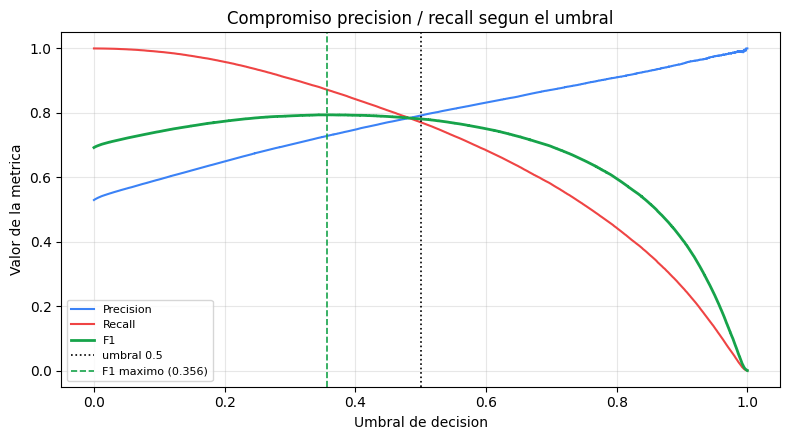


En un analisis real de fisica de altas energias, el umbral no se elige
maximizando F1 sino segun la significancia estadistica que se busque y el
presupuesto de computo disponible para analizar los eventos seleccionados.


In [11]:
precisiones, recalls, umbrales = precision_recall_curve(y_test, prob_stack)
f1s = 2 * precisiones * recalls / (precisiones + recalls + 1e-12)
i_mejor = int(np.nanargmax(f1s[:-1]))
umbral_f1 = float(umbrales[i_mejor])

i_eq = int(np.argmin(np.abs(precisiones[:-1] - recalls[:-1])))
umbral_eq = float(umbrales[i_eq])

print(f"{'Criterio':<28}{'Umbral':>9}{'Precision':>12}{'Recall':>10}{'F1':>10}")
print("-" * 69)
for nombre, u in [("por defecto", 0.5), ("maximiza F1", umbral_f1), ("precision = recall", umbral_eq)]:
    pred = (prob_stack >= u).astype(int)
    cmx = confusion_matrix(y_test, pred)
    tn2, fp2, fn2, tp2 = cmx.ravel()
    prec = tp2 / (tp2 + fp2); rec = tp2 / (tp2 + fn2)
    print(f"{nombre:<28}{u:>9.4f}{prec:>12.4f}{rec:>10.4f}{2*prec*rec/(prec+rec):>10.4f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(umbrales, precisiones[:-1], label="Precision", color="#3b82f6")
ax.plot(umbrales, recalls[:-1], label="Recall", color="#ef4444")
ax.plot(umbrales, f1s[:-1], label="F1", color="#16a34a", lw=2)
ax.axvline(0.5, color="black", ls=":", lw=1.2, label="umbral 0.5")
ax.axvline(umbral_f1, color="#16a34a", ls="--", lw=1.2, label=f"F1 maximo ({umbral_f1:.3f})")
ax.set_xlabel("Umbral de decision"); ax.set_ylabel("Valor de la metrica")
ax.set_title("Compromiso precision / recall segun el umbral")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
guardar_figura("umbral.png")
plt.show()

print("\nEn un analisis real de fisica de altas energias, el umbral no se elige")
print("maximizando F1 sino segun la significancia estadistica que se busque y el")
print("presupuesto de computo disponible para analizar los eventos seleccionados.")

In [12]:
# --- Resumen final y artefactos -------------------------------------------
resumen_final = df_comp.round(5).copy()
CSV_FINAL = TABLE_DIR / "comparacion_final_test.csv"
resumen_final.to_csv(CSV_FINAL)
espejar(CSV_FINAL)

print("RESUMEN FINAL — conjunto de Test")
print("=" * 72)
display(resumen_final)

for i, base in enumerate(DIRS_INFORME):
    etiqueta = "repositorio, versionada" if i == 0 else "copia de respaldo"
    print(f"\nEvidencia en {base}  [{etiqueta}]:")
    for p in sorted(base.rglob("*")):
        if p.is_file() and p.name != ".gitkeep":
            print(f"   {str(p.relative_to(base)):<36}"
                  f"{p.stat().st_size/1e3:>10.1f} KB")

print(f"\nCheckpoints en {CKPT_DIR}:")
for p in sorted(CKPT_DIR.glob("*.pt")):
    print(f"   {p.name:<36}{p.stat().st_size/1e3:>10.1f} KB")

mem_report("final")

RESUMEN FINAL — conjunto de Test


,ROC-AUC,PR-AUC,F1,Exactitud
Predictor,,,,
Modelo base 1,0.85316,0.86499,0.77918,0.76921
Modelo base 2,0.84880,0.86094,0.77860,0.76425
Modelo base 3,0.83279,0.84582,0.75891,0.74967
Promedio simple,0.85282,0.86469,0.78046,0.76893
STACKING,0.85572,0.86763,0.78115,0.77126



Evidencia en C:\Users\Admin\Desktop\Magister Informatica\Aprendizaje Profundo\Lab1-DL\reports  [repositorio, versionada]:
   figures\balance_clases.png                52.4 KB
   figures\curvas_modelos_base.png          172.4 KB
   figures\curvas_test.png                  120.1 KB
   figures\histogramas_variables.png        133.0 KB
   figures\kmeans.png                       331.4 KB
   figures\matriz_confusion.png              54.8 KB
   figures\matriz_correlacion.png            83.7 KB
   figures\meta_stacking.png                 48.4 KB
   figures\optuna_busqueda.png               54.7 KB
   figures\pca.png                          201.5 KB
   figures\tsne.png                         238.1 KB
   figures\umbral.png                        61.4 KB
   profiling\comparacion_particiones.html    3123.9 KB
   tables\comparacion_final_test.csv          0.3 KB

Evidencia en G:\Mi unidad\Lab1-DL\reports  [copia de respaldo]:
   figures\balance_clases.png                52.4 KB
   figures\curv

---
# Conclusiones y reflexión técnica

## 1. Evaluación crítica sobre el conjunto de Test

El conjunto de Test se abrió una sola vez, al final, con los 150.000 eventos que no intervinieron
en ninguna etapa previa: ni en el entrenamiento de los modelos base, ni en su Early Stopping, ni
en la búsqueda de hiperparámetros, ni en el ajuste de la meta-red. Los resultados son por tanto
una estimación insesgada del desempeño.

| Predictor | ROC-AUC | PR-AUC | F1 | Exactitud |
|---|---|---|---|---|
| Modelo base 1 (512-256-128) | 0,85316 | 0,86499 | 0,77918 | 0,76921 |
| Modelo base 2 (256-128-64) | 0,84880 | 0,86094 | 0,77860 | 0,76425 |
| Modelo base 3 (128-64) | 0,83279 | 0,84582 | 0,75891 | 0,74967 |
| Promedio simple | 0,85282 | 0,86469 | 0,78046 | 0,76893 |
| **Stacking** | **0,85572** | **0,86763** | **0,78115** | **0,77126** |

El Stacking obtiene el mejor valor en las cuatro métricas. Supera al promedio simple en **0,00290**
de ROC-AUC y al mejor modelo individual en **0,00256**.

### 1.1 El promedio simple empeoró el resultado

El dato más relevante de la tabla no es la ganancia del Stacking sino el fracaso de la alternativa
ingenua: **el promedio simple quedó por debajo del mejor modelo individual**, 0,85282 frente a
0,85316. Combinar los tres modelos dándoles el mismo voto produjo un predictor peor que quedarse
solo con el mejor de ellos.

La explicación está en la composición del ensamble. `base_3` alcanza 0,83279, unas dos centésimas
por debajo de `base_1`, y un promedio sin pesos le concede un tercio de la decisión. Lo que ese
tercio resta supera lo que la diversidad de los otros dos aporta. El resultado reproduce sobre Test
lo que ya se observaba sobre Validación en la Fase B, donde el promedio superaba al mejor
individual por apenas 0,0001: en Test la diferencia cambia de signo.

Esto delimita con precisión qué aportó el Stacking. No es que mejore mucho un buen resultado —la
ganancia absoluta es de dos milésimas y media de ROC-AUC—, sino que **evita un error que el
promedio simple sí comete**. En un ensamble cuyos miembros no son equivalentes, aprender los pesos
no es un refinamiento opcional: es lo que separa mejorar de empeorar.

### 1.2 Los pesos aprendidos ordenaron a los modelos por competencia

| Modelo | Peso aprendido | Peso relativo | ROC-AUC individual (Validación) |
|---|---|---|---|
| base_1 | **+0,6401** | 55,9 % | 0,85341 |
| base_2 | **+0,4547** | 39,7 % | 0,84993 |
| base_3 | **−0,0493** | 4,3 % | 0,83332 |
| sesgo | −0,0469 | — | — |

La meta-red ordenó a los tres modelos **exactamente según su competencia individual**, sin que esa
información se le proporcionara: solo vio las predicciones de cada uno sobre el conjunto de
Validación. El modelo más preciso recibió más del doble del peso que el intermedio, y el más débil
quedó prácticamente excluido.

El signo negativo de `base_3` merece atención, porque no es un defecto. Un peso negativo significa
que la meta-red no lo usa como un voto más, sino **como corrector**: resta parte de su predicción
a la combinación de los otros dos. Es el comportamiento esperable de un modelo que subajusta —su
dropout de 0,440 sobre la red más pequeña le impidió aprender— y que, por lo mismo, sistematiza
sus errores de un modo que resulta informativo restarlo. Un promedio simple es incapaz de
expresar esa relación, porque sus pesos son positivos e iguales por definición.

Vale registrar también lo que la meta-red **no** necesitó: solo 4 parámetros entrenables frente a
los 262.019 congelados de los modelos base, es decir, el 0,0015 % del total. El Stacking no vuelve
a aprender el problema; aprende únicamente cómo combinar lo ya aprendido, y le bastaron 11 segundos
y 22 épocas para hacerlo.

### 1.3 Lectura en el contexto del experimento

Con el umbral por defecto de 0,5, sobre los 150.000 eventos de Test:

- De las **79.431 colisiones de señal**, el modelo detectó **61.235 (77,09 %)** y perdió 18.196
  (22,91 %) clasificándolas como fondo.
- De las **70.569 colisiones de fondo**, descartó correctamente **54.454 (77,16 %)** y dejó pasar
  16.115 (22,84 %), que contaminan la muestra seleccionada.
- De cada 100 eventos que el modelo marca como señal, **79,2 son efectivamente señal**.

Ambos errores tienen costos distintos y no intercambiables. Un **falso negativo** es una colisión
de Higgs descartada: tiempo de acelerador gastado en un evento que luego se ignora. Un **falso
positivo** contamina la muestra y diluye la significancia estadística del análisis posterior. La
simetría casi perfecta de este resultado —77,09 % de recall frente a 77,16 % de especificidad— no
es una propiedad deseable por sí misma, sino la consecuencia de haber fijado el umbral en 0,5 sin
un criterio físico.

El análisis de umbrales muestra el margen de maniobra disponible:

| Criterio | Umbral | Precisión | Recall | F1 |
|---|---|---|---|---|
| Por defecto | 0,5000 | 0,7917 | 0,7709 | 0,7812 |
| Maximiza F1 | 0,3565 | 0,7285 | **0,8723** | **0,7939** |
| Precisión = recall | 0,4826 | 0,7840 | 0,7840 | 0,7840 |

Bajar el umbral a 0,3565 recupera **10 puntos de recall** —del 77,1 % al 87,2 %— a cambio de
6,3 puntos de precisión. En un análisis real esa elección no se resuelve maximizando F1, que es
una métrica agnóstica al dominio, sino en función de la significancia estadística buscada y del
presupuesto de cómputo disponible para procesar los eventos seleccionados.

## 2. Por qué esta arquitectura resolvió el problema

El notebook 01 estableció, antes de entrenar nada, que el problema no admitía soluciones simples.
El ARI de K-Means frente a la etiqueta real fue de **0,0085**, prácticamente cero: el agrupamiento
por distancia euclidiana no guarda ninguna relación con la división física entre señal y fondo. El
PCA requirió **20 de 28 componentes** para explicar el 90 % de la varianza, con las dos primeras
capturando apenas el 21,1 %. Y en los histogramas, las 21 variables cinemáticas de bajo nivel
mostraban distribuciones casi superpuestas entre ambas clases.

Ese diagnóstico descartaba tanto los métodos lineales como el agrupamiento por distancia, y
justificaba una red capaz de representar interacciones no lineales entre variables. El resultado
final —ROC-AUC de 0,856 sobre datos que ningún método no supervisado lograba separar— confirma
que el diagnóstico era correcto y que la arquitectura elegida era la adecuada.

El *feature engineering* contribuyó de forma verificable: **9 de las 15 variables más
correlacionadas con la etiqueta son construidas en la Fase B**, y el cociente `m_wbb_over_m_wwbb`
(0,1391) supera a `m_wwbb` (0,1243), que es una de las dos masas con las que se construye. La
información discriminante reside en la proporción entre sistemas físicos, no en su magnitud
absoluta —que depende de la energía total del evento y por eso introduce variabilidad ajena a la
clase.

En conjunto, el trabajo reproduce a escala de laboratorio la hipótesis central de Baldi, Sadowski
y Whiteson (2014) [1]: que el aprendizaje profundo puede extraer de las variables del detector la
información que los físicos obtenían construyendo variables derivadas a mano.

## 3. Desafíos de hardware, tiempo y memoria

**El entrenamiento se ejecutó íntegramente en CPU**, sin GPU disponible, con PyTorch 2.15.0+cpu
sobre 8 hilos. Esa restricción condicionó todas las decisiones de dimensionamiento.

El costo medido por época sobre 700.000 filas va de **1,52 s** con la arquitectura más pequeña a
**10,16 s** con la mayor. La búsqueda de hiperparámetros sobre el 100 % de los datos habría
demandado algo más de **80 minutos** para 30 intentos; ejecutarla sobre el 20 % la redujo a
**16,9 minutos**, y el `MedianPruner` evitó además completar 7 de esos 30 intentos. El *pruning*
no fue un refinamiento sino una condición de viabilidad: sin él, el presupuesto de cómputo no
habría alcanzado para explorar 30 configuraciones.

El tiempo total acumulado de entrenamiento fue de aproximadamente **32 minutos**: 16,9 de búsqueda,
14,6 de los tres modelos base y 11 segundos de la meta-red. Queda holgadamente dentro del
presupuesto de 12 a 24 horas que fija el enunciado, y buena parte de ese margen se debe
precisamente al esquema de búsqueda progresiva.

**La memoria fue la restricción más severa, y la del notebook 01.** El archivo descomprimido ocupa
7,5 GB; la lectura por bloques de 1.000.000 de filas, con casteo a `float32` y liberación explícita
mediante `del` y `gc.collect()`, mantuvo el proceso en un máximo de **0,94 GB**, menos del 13 % del
tamaño del archivo. Una lectura directa con `pd.read_csv()` habría intentado materializar las
11.000.000 de filas en memoria y, con la descompresión del `.gz` ocurriendo en el mismo proceso,
el desenlace habitual es la terminación de la sesión por agotamiento de memoria. No se trató de
una optimización opcional: era la condición para que el pipeline corriera.

Los picos por fase fueron de 0,94 GB en la Fase A, **1,35 GB** en la Fase B —alcanzado tras la
búsqueda de Optuna, que mantiene en memoria los tensores de entrenamiento y los del subconjunto de
búsqueda— y 0,88 GB en la Fase C. Todos holgadamente por debajo de los ~12 GB del nivel gratuito
de Google Colab.

Una observación sobre el rendimiento marginal de la capacidad: `base_1` necesitó **9,0 minutos**
para superar a `base_2` en 0,0035 de ROC-AUC, con 3,5 veces más parámetros y 2,4 veces más tiempo.
En este problema, la capacidad adicional rinde poco, lo que concuerda con la importancia de
hiperparámetros que reportó Optuna: el dropout explicó el 88,5 % de la variación del objetivo y la
arquitectura solo el 0,9 %.

## 4. Qué se haría distinto

**Diversificar también la regularización, no solo la arquitectura.** La decisión de dar a cada
modelo base una arquitectura distinta resultó acertada —sin ella los tres modelos habrían sido
equivalentes y el Stacking no habría tenido nada que ponderar—, pero los datos sugieren que el
criterio podía afinarse. Optuna identificó el dropout como el hiperparámetro dominante, de modo
que diversificar explícitamente ese eje, en lugar de la arquitectura, probablemente habría
producido modelos con errores aún menos correlacionados.

**Revisar la selección del tercer modelo.** `base_3` combinó la red más pequeña con el dropout más
alto (0,440) y terminó subajustando, hasta el punto de recibir un peso negativo en la meta-red.
Elegir las tres mejores configuraciones *con arquitecturas distintas* forzó a incluir una
configuración que la búsqueda ya había ordenado como netamente inferior. Un criterio alternativo
—por ejemplo, exigir que las configuraciones elegidas no difieran en más de cierto margen de AUC
respecto de la mejor— conservaría la diversidad sin incorporar un miembro débil.

**Explorar un meta-aprendiz no lineal.** La meta-capa actual es lineal, con 4 parámetros. Una
meta-red con una capa oculta podría capturar interacciones entre las predicciones de los modelos
base —por ejemplo, confiar en `base_2` solo cuando `base_1` es incierto—, aunque el riesgo de
sobreajustar sobre el conjunto de Validación crece con cada parámetro añadido, y la ganancia
disponible, a juzgar por estos resultados, es de milésimas.

**Aprovechar el conjunto Out-Of-Bag.** Cada muestra Bootstrap dejó fuera el 36,8 % de las
observaciones. Ese conjunto permite estimar el error de cada modelo base sin consumir el de
Validación, lo que habría dejado más datos disponibles para el ajuste de la meta-red.

## 5. Síntesis

El pipeline completo procesa 1.000.000 de colisiones, construye 23 variables derivadas, selecciona
hiperparámetros mediante búsqueda progresiva sobre el 20 % de los datos, entrena tres redes
profundas sobre muestras Bootstrap distintas y las combina mediante una meta-red de pesos
entrenables, alcanzando un **ROC-AUC de 0,85572 sobre un conjunto de Test de 150.000 eventos jamás
utilizado durante el desarrollo**. Todo ello en unos 32 minutos de cómputo en CPU y con un consumo
máximo de memoria de 1,35 GB.

---
# Referencias

Bibliografía completa, con el detalle de dónde se usa cada entrada, en
[`docs/REFERENCIAS.md`](../docs/REFERENCIAS.md).

**[1]** Baldi, P., Sadowski, P. y Whiteson, D. (2014). *Searching for exotic particles in
high-energy physics with deep learning*. **Nature Communications 5**, artículo 4308.
DOI: [10.1038/ncomms5308](https://doi.org/10.1038/ncomms5308)

**[5]** Glorot, X. y Bengio, Y. (2010). *Understanding the difficulty of training deep feedforward
neural networks*. **AISTATS 2010**, PMLR 9, 249–256.
<https://proceedings.mlr.press/v9/glorot10a.html>

**[11]** Breiman, L. (1996). *Bagging predictors*. **Machine Learning 24**(2), 123–140.
DOI: [10.1007/BF00058655](https://doi.org/10.1007/BF00058655)

**[13]** Wolpert, D. H. (1992). *Stacked generalization*. **Neural Networks 5**, 241–259.
Publicado por Elsevier; volumen y páginas verificados, DOI no confirmado.

**[17]** Paszke, A. *et al.* (2019). *PyTorch: an imperative style, high-performance deep learning
library*. **NeurIPS 32**. [arXiv:1912.01703](https://arxiv.org/abs/1912.01703)

**[18]** Pedregosa, F. *et al.* (2011). *Scikit-learn: machine learning in Python*. **JMLR 12**,
2825–2830. <https://jmlr.org/papers/v12/pedregosa11a.html>